# nbev on multiple-choice questions

**nbev** (packed DeBERTa + decision head, built step by step in [`deberta_full_walkthrough.ipynb`](deberta_full_walkthrough.ipynb)) trained on the dataset's **`choice` questions only**: pick the right option, among 2 to 10, for a text state. Yes/no and score questions are left out, so there is one question type, one temperature and one main metric (accuracy).

| step | what we did | code |
|---|---|---|
| 1. Data | all ~98K choice training questions; validation, calibration and test never share a state with training | `dataset.py`, `data.task_types: [choice]` |
| 2. Model | DeBERTa-v3-base reads each question as **one** packed sequence; a small head compares the options | `architectures/nbev/`, `architectures/choice_head.py` |
| 3. Training | full fine-tuning, 1 epoch, ~2 h on an M-series Mac, run outside the notebook | `train.py`, `configs/choice_full.yaml` |
| 4. Calibration | one temperature, fitted on the calibration split | `calibration.py` |
| 5. Test | 5,000 test questions, measured once | `metrics.py` |
| 6. Speed | one forward pass per question, whatever the number of options | `notebook_utils.py` |
| 7. Predictions | random test questions and the most confident mistakes | `notebook_utils.py` |
| 8. Hands-on | ask your own questions | `inference.py` |

This notebook never trains: it loads the finished run, and caches the model outputs next to its checkpoint (first run ~10 min, then ~1 min).

In [1]:
import json

import pandas as pd
import yaml

from architectures import get_architecture
from calibration import fit_temperatures, save_temperatures
from dataset import QuestionDataset, load_questions
from inference import get_device
from logger import load_checkpoint
from metrics import compute_metrics
from notebook_utils import (accuracy_by, ask, evaluate_split, inference_speed, latest_run, layer_summary,
                            parameter_table, plot_calibration, plot_training_curves, read_metrics, show_model_input,
                            show_predictions, show_question)

CONFIG_PATH = "configs/choice_full.yaml"   # all ~98K choice training questions, one epoch
RUN_NAME = "nbev-choice-full"              # loaded from runs/nbev-choice-full-<timestamp>/, never retrained here
NUM_CALIBRATION, NUM_TEST = None, 5000     # all ~1,900 calibration questions; 5,000 of the ~18,800 test ones

config = yaml.safe_load(open(CONFIG_PATH))
device, d = get_device(), config["data"]
pd.options.display.float_format = "{:.4f}".format
print(f"device: {device}, task types: {d['task_types']}")

device: mps, task types: ['choice']


## 1. Data

[`avbiswas/bev-decision-150K`](https://huggingface.co/datasets/avbiswas/bev-decision-150K): each row is a text **state** (a support ticket, a code issue, a comment, a puzzle, a product page, …) with questions about it. A `choice` question has an instruction and named options, given to the model as `"key: description"`; the label is the correct option.

Splits are assigned by an md5 hash of the state text: validation and calibration are each 2% of the dataset's train split, the test split is the dataset's own. No state is in two splits, so the model is never evaluated on a state it was trained on (exact overlap test/train: 0).

| split | used for |
|---|---|
| train | learning the weights (all of it, once) |
| validation | picking the best checkpoint during training |
| calibration | fitting the temperature after training |
| test | the final numbers, measured once |

In [2]:
counts = {split: len(load_questions(split, None, config["seed"], d["task_types"]))
          for split in ("train", "validation", "calibration", "test")}
pd.Series(counts, name="choice questions").to_frame()

,choice questions
train,98085
validation,2006
calibration,1943
test,18808


In [3]:
test_questions = load_questions("test", NUM_TEST, config["seed"], d["task_types"])
print(f"{len(test_questions)} test questions used; options per question:",
      dict(sorted(pd.Series([len(c) for c in test_questions["choices"]]).value_counts().items())))
pd.Series(test_questions["domain"]).value_counts().to_frame("test questions")

5000 test questions used; options per question: {2: 473, 3: 972, 4: 1996, 5: 177, 6: 552, 7: 33, 8: 648, 10: 149}


,test questions
Spatial and logical reasoning,1592
Support and intent routing,762
"Retail, product, and shopping",612
Tool and workflow decisions,582
Software engineering and code,537
"Sentiment, emotion, and moderation",295
Response preference and quality,184
Scientific and paper understanding,122
Contract evidence,95
Browser interaction,83


Three questions as stored in the dataset (→ = correct answer):

In [4]:
for i in (0, 7, 123):
    show_question(test_questions[i])

[choice] Which emotion did source annotators assign to this comment?
   state: I'm sorry man sounds bad …
   → 0. sadness: sadness
     1. anger: anger
     2. nervousness: nervousness
     3. grief: grief

[choice] Which test fails on the buggy version and passes after the fix?
   state: dicomfile iterator broken after recent changes  #### Description  The `dicomfile` class in `util/leanread.py` is not working properly. When trying to iterate over DICOM elements, it fails with various errors depending on the file type.  #### Steps/Code to Reproduce  ```python from pydicom.util.leanr …
     0. test_0: tests/test_util.py::TestCodify::test_camel_to_underscore
     1. test_1: tests/test_util.py::TestDump::test_pretty_print
   → 2. test_2: tests/test_util.py::TestLeanRead::test_explicit_big
     3. test_3: tests/test_util.py::TestCodify::test_code_sequence

[choice] What is the intent of this citation?
   state: Most studies compare different surgical techniques and focus on the complicati

## 2. Model

```
[CLS] task hint + question + state [SEP]  [OPT] option A [SEP]  [OPT] option B [SEP]  ...
positions 0 ................... n-1        n    n+1 ...          n    n+1 ...           options share positions
                     |
              DeBERTa-v3-base             12 layers, all fine-tuned; an option sees the context and itself only
                     |
        hA          hB          ...       one 768-d vector per option: its [OPT] token's output
        +-- self-attention between options (x2) --+     the only place where options are compared
        zA          zB          ...       the same MLP gives each option one score (logit)
               softmax(z / T)             calibrated probabilities
```

- **One sequence per question.** The context is encoded once, however many options there are (BEV's packing).
- **Shared positions + attention mask.** Every option restarts at position `n`, and its tokens see the context and themselves, never another option: each option is read as if it were alone, and the option order cannot change the answer.
- **`[OPT]` pooling.** Each option starts with an `[OPT]` token that attends to all of the option's tokens; its output represents the option.
- **Decision head (`candidate_mlp`).** 2 self-attention blocks over the option vectors (no positions), then a shared MLP 768 → 512 → 1.
- **Long states** (over 448 tokens) keep their first 64 tokens and their end, where the part being judged usually is.

The attention mask is drawn in [`deberta_full_walkthrough.ipynb`](deberta_full_walkthrough.ipynb). What the model actually reads for the second question above, decoded from its token ids:

In [5]:
arch = get_architecture(config)
show_model_input(arch, test_questions[7], d, max_context_chars=900)

=== choice | 401 tokens: context = positions 0..295, 4 candidate blocks ===
[CLS] Choose the best option. Question: Which test fails on the buggy version and passes after the fix? dicomfile iterator broken after recent changes #### Description The `dicomfile` class in `util/leanread.py` is not working properly. When trying to iterate over DICOM elements, it fails with various errors depending on the file type. #### Steps/Code to Reproduce ```python from pydicom.util.leanread import dicomfile from pydicom.data import get_
      [... 182 characters not printed here, but read by the model ...]
 has no attribute 'preamble'` when trying to access the preamble attribute. Also trying with implicit VR files: ```python p = get_testdata_file('MR_small_implicit.dcm') with dicomfile(p) as ds: for elem in ds: pass ``` Results in `UnboundLocalError: cannot access local variable 'file_meta' where it is not defined` when iterating. The dicomfile context manager used to work for reading DICOM files in 

## 3. Training

| | setting | why |
|---|---|---|
| data | 98,085 questions, 1 epoch, batches of questions of similar length | less padding |
| batch | 8 questions × 2 accumulation steps = 16 per optimizer step → 6,130 steps | |
| optimizer | AdamW; weight decay 0.01 on weight matrices only, not on biases and LayerNorms | standard practice |
| learning rates | DeBERTa 3e-5, head 1e-3 | pretrained weights vs random init |
| schedule | linear warm-up over 10% of the steps, then cosine decay to 0 | |
| stability | gradient clipping at 1.0; bf16 autocast, head in fp32 | |
| selection | every 500 steps on all ~2,000 validation questions; best = **lowest NLL** | we use the probabilities |
| resumable | `checkpoints/latest` every 500 steps: weights, optimizer, schedule, data position | `--continue_run` |

The run is launched in a terminal (while the Mac is awake: `caffeinate -i` keeps it awake, it cannot wake a sleeping Mac):
```
caffeinate -i uv run python train.py configs/choice_full.yaml --name nbev-choice-full
```
If it stops, `--continue_run runs/nbev-choice-full-<timestamp>` resumes exactly where `checkpoints/latest` was saved.

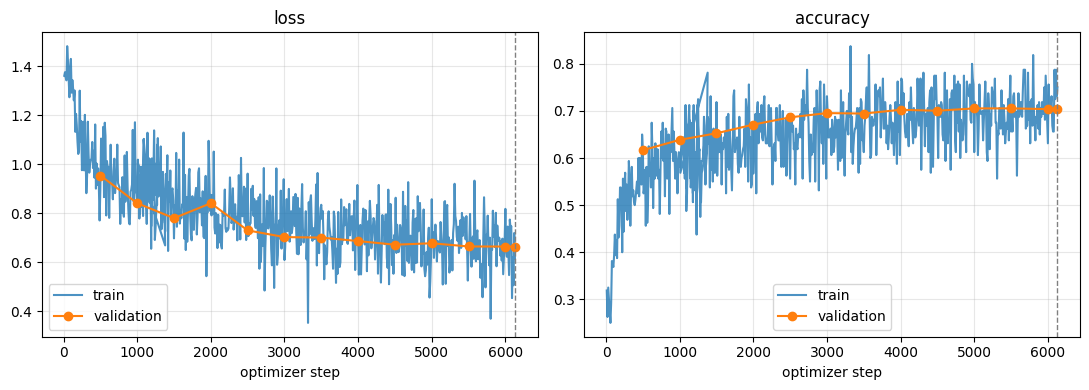

In [6]:
run_dir = latest_run(RUN_NAME)
assert run_dir is not None, f"no finished {RUN_NAME} run yet: train it first (command above)"
plot_training_curves(run_dir)

In [7]:
validation = pd.DataFrame(read_metrics(run_dir)["validation"]).set_index("step")
validation[["loss", "accuracy", "ece_choice"]].rename(columns={"loss": "NLL", "ece_choice": "ECE (T = 1)"})

,NLL,accuracy,ECE (T = 1)
step,,,
500,0.9542,0.6167,0.0827
1000,0.8412,0.6386,0.0431
1500,0.7801,0.6525,0.0351
2000,0.8412,0.6710,0.0643
2500,0.7304,0.6864,0.0483
3000,0.7030,0.6954,0.0344
3500,0.7010,0.6944,0.0323
4000,0.6868,0.7024,0.0209
4500,0.6719,0.7004,0.0173


Validation NLL falls at almost every check and accuracy levels off around 0.70 from step ~4,000, as the cosine schedule takes the learning rate to 0. Each train point averages only 160 questions, hence the noise; the epoch's average train loss (0.75) is above the final validation NLL (0.66) because it includes the early steps: no over-fitting. A pilot on 10K choice questions reached 0.62 on the same test questions: 10× more data gave about +9 points.

The best checkpoint, with its parameters:

In [8]:
best_dir = run_dir / "checkpoints" / "best"
network, config = load_checkpoint(best_dir, device)
print(f"{best_dir}  (step {json.loads((best_dir / 'meta.json').read_text())['step']})")
parameter_table(network)

runs/nbev-choice-full-20261122-223705/checkpoints/best  (step 6130)


,block,type,parameters,trainable
0,backbone.embeddings,DebertaV2Embeddings,"98,382,336","98,382,336"
1,backbone.encoder,DebertaV2Encoder,"85,449,216","85,449,216"
2,head.input_norm,LayerNorm,"1,536","1,536"
3,head.layers,ModuleList,"4,731,904","4,731,904"
4,head.final_norm,LayerNorm,"1,536","1,536"
5,head.scorer,Sequential,"394,241","394,241"
6,total,,"188,960,769","188,960,769"


**Layer by layer** ([torchinfo](https://github.com/TylerYep/torchinfo)), from one forward pass on 4 test questions. `B` = 4 questions, one packed sequence of `L` tokens each, `C` = the most options any of them has.

In [9]:
batch = arch.collate_fn([QuestionDataset(test_questions, arch.encode_example, d["max_state_tokens"], d["max_choice_tokens"])[i]
                         for i in range(4)])
print({key: tuple(value.shape) for key, value in batch.items()}, "\n")
layer_summary(network, batch, device)

{'input_ids': (4, 204), 'position_ids': (4, 204), 'padding_mask': (4, 204), 'attention_mask': (4, 204, 204), 'opt_idx': (4, 4), 'choice_token_mask': (4, 4, 204), 'choice_mask': (4, 4), 'task_type': (4,), 'labels': (4,)} 

Layer (type (var_name))                                                Output Shape              Param #
NBEVNetwork (NBEVNetwork)                                              [4, 4]                    --
├─DebertaV2Model (backbone)                                            --                        --
│    └─DebertaV2Embeddings (embeddings)                                [4, 204, 768]             --
│    │    └─Embedding (word_embeddings)                                [4, 204, 768]             98,380,800
│    │    └─LayerNorm (LayerNorm)                                      [4, 204, 768]             1,536
│    │    └─Dropout (dropout)                                          [4, 204, 768]             --
│    └─DebertaV2Encoder (encoder)                             

| head row | what it does |
|---|---|
| `input_norm` | normalises the `[OPT]` vectors `[B, C, 768]` |
| `AttentionBlock` ×2: `norm1` → `attn` | options attend to each other (padded slots masked), residual |
| `AttentionBlock` ×2: `norm2` → `mlp` | per-option MLP 768 → 512 → 768 (GELU), residual |
| `final_norm` → `scorer` | MLP 768 → 512 → **1**: one logit per option, `[B, C]` |

## 4. Calibration

We use the probabilities, not only the top answer, so they must be **calibrated**: of the answers given with 70% confidence, about 70% should be right. **Temperature scaling** divides the logits by one number, `p = softmax(z / T)`, fitted on the calibration split (used neither for training nor for picking the checkpoint). T > 1 softens the probabilities, T < 1 sharpens them; the top answer never changes.

`NLL` = mean −log p(correct answer), lower is better. `ECE` = average gap between confidence and accuracy, 0 = calibrated.

In [10]:
calibration = evaluate_split(network, config, best_dir, "calibration", NUM_CALIBRATION, device)  # cached after the first run
if isinstance(network.temperature, dict):   # calibration.json already exists: keep it, don't overwrite
    temperatures = network.temperature
else:
    temperatures = fit_temperatures(calibration["logits"], calibration["labels"], calibration["task_types"])
    save_temperatures(best_dir, temperatures, split="calibration", num_questions=len(calibration["labels"]))
    network.temperature = temperatures       # ask() uses it from now on
print(f"T = {temperatures['choice']:.3f}  (fitted on {len(calibration['labels'])} calibration questions)")
pd.DataFrame({"before (T = 1)": compute_metrics(calibration["logits"], calibration["labels"], calibration["task_types"]),
              "after": compute_metrics(calibration["logits"], calibration["labels"], calibration["task_types"], temperatures)}).T

T = 1.253  (fitted on 1943 calibration questions)


,loss,accuracy,accuracy_choice,nll_choice,ece_choice
before (T = 1),0.6794,0.6989,0.6989,0.6794,0.0423
after,0.6725,0.6989,0.6989,0.6725,0.0231


## 5. Test

Measured once, after every decision (checkpoint, temperature) was made on other splits. On 5,000 questions the accuracy is known to about ±1.3 points (95%). The result is saved to `runs/<run>/test_metrics.json` unless that file already exists.

In [11]:
test = evaluate_split(network, config, best_dir, "test", NUM_TEST, device)  # cached after the first run
test_metrics = compute_metrics(test["logits"], test["labels"], test["task_types"], temperatures)
results_file = run_dir / "test_metrics.json"
if not results_file.exists():
    results_file.write_text(json.dumps({"checkpoint": str(best_dir), "temperatures": temperatures,
                                        "num_questions": len(test["labels"]), "metrics": test_metrics}, indent=2))
pd.DataFrame({"questions": len(test["labels"]), "accuracy": test_metrics["accuracy_choice"],
              "chance": (1 / pd.Series([len(c) for c in test_questions["choices"]])).mean(),
              "NLL": test_metrics["nll_choice"], "ECE": test_metrics["ece_choice"]}, index=["test (calibrated)"])

,questions,accuracy,chance,NLL,ECE
test (calibrated),5000,0.7078,0.2575,0.6716,0.0177


**Reliability diagram**: test questions grouped by the model's confidence in its top answer (x), against how often that answer is right (y). On the diagonal = calibrated; below = over-confident.

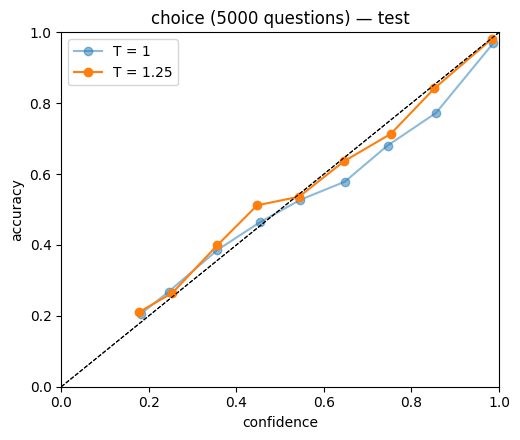

In [12]:
plot_calibration(test, temperatures, title_suffix=" — test")

### By number of options and by domain

`gain` = accuracy − chance. Groups under ~100 questions are noisy (±0.1).

In [13]:
test_questions = test_questions.add_column("options", [len(c) for c in test_questions["choices"]])
accuracy_by(test, test_questions, "options", temperatures).droplevel("task").sort_index()

,questions,accuracy,chance,gain
options,,,,
2,473,0.7759,0.5000,0.2759
3,972,0.6975,0.3333,0.3642
4,1996,0.7981,0.2500,0.5481
5,177,0.7853,0.2000,0.5853
6,552,0.5942,0.1667,0.4275
7,33,0.9091,0.1429,0.7662
8,648,0.4151,0.1250,0.2901
10,149,0.9060,0.1000,0.8060


In [14]:
accuracy_by(test, test_questions, "domain", temperatures).droplevel("task")

,questions,accuracy,chance,gain
domain,,,,
Spatial and logical reasoning,1592,0.5433,0.2307,0.3126
Support and intent routing,762,0.9685,0.2452,0.7233
"Retail, product, and shopping",612,0.4412,0.2119,0.2293
Tool and workflow decisions,582,0.9948,0.3013,0.6936
Software engineering and code,537,0.6853,0.2500,0.4353
"Sentiment, emotion, and moderation",295,0.8508,0.2500,0.6008
Response preference and quality,184,0.6413,0.5000,0.1413
Scientific and paper understanding,122,0.8934,0.3333,0.5601
Contract evidence,95,0.6316,0.3333,0.2982


**Reading the test.** 0.71 accuracy against 0.26 for chance, and calibrated: T = 1.25 > 1 means the raw model was slightly over-confident; after it, ECE ≈ 0.02. The kind of question matters more than the number of options, since each option count comes mostly from a few domains (all 8-option questions are spatial puzzles):

- **Nearly solved** when the answer is a match or a classification: tool choice (0.99), intent routing (0.97), citation intent (0.89), browser actions (0.87), emotions (0.85).
- **Hard** when the answer must be computed from the state: spatial and logical puzzles (0.54, a third of the test questions) and retail invoices (0.44: "largest quantity × unit price", "cheapest per unit"). One forward pass of a 184M-parameter encoder handles arithmetic and multi-step spatial reasoning poorly; a larger backbone would most likely help there first.

## 6. Inference speed

End to end (tokenization + one forward pass + softmax), after warm-up, batches of similar length. First table: per question, one at a time or 8 at once. Second: one question with 2 to 32 options; the context is encoded once, so each extra option only adds its own short block.

In [15]:
by_batch, by_candidates = inference_speed(network, config, device, test_questions)
display(by_batch, by_candidates)

,ms per question,questions per second,mean tokens per question
batch size,,,
1,28.1099,35.5746,168.3906
8,27.2761,36.6621,168.3906


,tokens,ms per question
candidates,,
2,108,12.0462
4,132,13.8350
8,180,17.7991
16,276,31.4554
32,468,86.3154


## 7. Predictions on test questions

Calibrated probabilities for each option; → marks the correct answer. Random questions first:

In [16]:
show_predictions(test, test_questions, temperatures, n=5, seed=0)

[Spatial and logical reasoning] What is to the right of the big yellow circle? a medium black square or a blue circle?
   ✗ wrong, confidence 0.56
   state: There are two blocks, A and B. Block A has a small yellow circle and a medium black square. To the left of and above a big yellow circle there is a medium blue circle. The small yellow circle is touch … o a big black square in this block. To the right of the medium black square is the big black square.
   → 0.261  ████████                        option_0: medium black square
     0.132  ████                            option_1: blue circle
     0.559  █████████████████               option_2: both of them
     0.048  █                               option_3: none of them

[Tool and workflow decisions] Which service tool fits this request?
   ✓ right, confidence 1.00
   state: USER: I need to have dinner with a client in Indianapolis tomorrow afternoon. Can you book me a table for two at Bluebeard? It'll be for Thursday 4/4/2019. Le

### The most confident mistakes

The wrong answers the model was surest about. Most are ambiguous labels rather than clear errors: `datetime_query` vs `datetime_convert` for time-zone questions, or a single annotator's emotion where the model's label fits as well.

In [17]:
show_predictions(test, test_questions, temperatures, n=4, mistakes=True)

[Support and intent routing] Which intent best matches the request “if i was in the eastern time zone what time would it be”?
   ✗ wrong, confidence 1.00
   state: if i was in the eastern time zone what time would it be
     0.000                                  transport_taxi: transport taxi
   → 0.000                                  datetime_convert: datetime convert
     1.000  ██████████████████████████████  datetime_query: datetime query
     0.000                                  iot_hue_lightchange: iot hue lightchange

[Support and intent routing] Which intent should be assigned to a request asking about the time difference between the user’s location and Hong Kong?
   ✗ wrong, confidence 1.00
   state: what is the time difference between my location and hong kong
   → 0.000                                  datetime_convert: datetime convert
     0.000                                  qa_currency: qa currency
     0.000                                  play_podcasts: play pod

## 8. Ask your own questions

`ask(network, config, device, state, instructions, "choice", criteria)` prints the calibrated answer; `criteria = {"option": "description", …}` (descriptions may be empty).

In [18]:
ask(network, config, device,
    state="Hi, I was charged twice for my March invoice (order #4821). Please refund one of the payments.",
    instructions="Which department should handle this ticket?", task_type="choice",
    criteria={"Billing": "payments, invoices, refunds", "Technical": "bugs, outages, login problems",
              "Sales": "new purchases, upgrades, pricing questions"});

[choice] Which department should handle this ticket?
    1.000  ██████████████████████████████  Billing
    0.000                                  Technical
    0.000                                  Sales

